# 12 · 실험 결과 읽기 — 세 조건을 공정하게 비교하고 해석하기

> 결과를 읽을 때는 "무엇을 같게 두고 무엇을 바꿨는지"를 먼저 확인하고, 지표마다 "무엇을 기준으로 잰 값인지"를 확인해야 한다. 그래야 말할 수 있는 것과 말할 수 없는 것이 구분된다.

**지금 위치**

01~04 기초·MPC → 05~07 MPPI → 08~09 로봇팔 → 10 지도 → 11 손 비용 → **12 결과 읽기** → 13 Isaac Sim 실습

**이 노트를 끝내면**
1. 세 조건(R / LOW / HIGH)이 공정한 비교인 이유와, 각 비교가 무엇의 효과를 보여 주는지 설명할 수 있다.
2. 최소 이격(버퍼 포함/제외), 경로, 도달 시간, 추종 오차를 실험 로그에서 직접 계산할 수 있다.
3. 이 결과로 주장할 수 있는 것과 주장할 수 없는 것을 구분할 수 있다.

**필요한 것:** [08](08_robot_arm.ipynb)의 충돌 구, [09](09_curobo_franka.ipynb)의 buffer 20 mm와 상태 필터, [11](11_hand_cost_mass.ipynb)의 세 조건과 η 정책 · **예상 시간:** 40분

## 복습 퀴즈 (11 노트)

<details><summary>1. R, LOW, HIGH 조건은 각각 무엇이 다른가?</summary>

R은 손 전용 비용이 없다(지도 기반 환경 충돌 비용만 있다). LOW와 HIGH는 손 관측 패치에 손 전용 충돌 비용을 더하고, 그 비용이 켜지는 거리 η만 다르다(LOW 25 mm, HIGH 73.52 mm).
</details>

<details><summary>2. η가 73.52 mm이면 로봇은 손에서 73.52 mm 이상 떨어져 지나가는가?</summary>

아니다. η는 비용이 0이 아니게 되는 거리일 뿐이다. 비용은 soft cost라서 목표 비용과 절충되고, 더 가까이 가는 후보가 선택될 수 있다.
</details>

<details><summary>3. cuRobo의 feasible 판정에 손 전용 비용이 들어가는가?</summary>

들어가지 않는다. 손 비용은 MPPI 총비용에만 더해지고, feasible은 관절 한계 같은 기존 제약 검사만 본다.
</details>

In [1]:
import csv
import numpy as np
from common import *
plt = setup_plot()

FILES = ['metrics.jsonl', 'arrival-events.jsonl', 'goal-events.jsonl', 'summary.json',
         'control-settings.json', 'failure-events.json', 'mass-policy.json', 'patches-per-frame.jsonl']

def load(c):
    d = {}
    for f in FILES:
        p = EVIDENCE / c / f
        d[f.split('.')[0]] = read_jsonl(p) if f.endswith('.jsonl') else json.loads(p.read_text())
    return d

E = {c: load(c) for c in CONDITIONS}          # CONDITIONS = ['R', 'LOW', 'HIGH']

def col(c, key):
    # metrics.jsonl의 한 열을 numpy 배열로 (None은 NaN)
    return np.array([np.nan if r[key] is None else r[key] for r in E[c]['metrics']], dtype=float)

print('조건별 기록 스텝 수:', {c: len(E[c]['metrics']) for c in CONDITIONS})

조건별 기록 스텝 수: {'R': 472, 'LOW': 472, 'HIGH': 472}


`evidence/` 폴더에는 Isaac Sim에서 실제로 돌린 세 조건의 원본 로그가 있다. 이 노트에서는 시뮬레이터를 다시 돌리지 않고 **로그만으로** 결과를 다시 계산한다. `metrics.jsonl`은 매 물리 스텝(1/60초)마다 한 줄씩, 실제 관절 각도·명령·EE 위치·이격 등을 기록한 파일이다.

## 1. 공정한 비교 — 무엇을 같게 두고 무엇을 바꿨나

### 문제
세 번 실행했더니 결과가 다르다. 그 차이가 손 비용 때문인지, 아니면 카메라 영상이 조금 달랐거나 MPPI의 무작위 샘플이 달랐기 때문인지 어떻게 알 수 있을까?

### 아이디어
**한 가지만 바꾸고 나머지는 모두 같게** 두면 된다. 이 실험은 그렇게 설계되어 있다.

| 같게 둔 것 | 어떻게 |
|---|---|
| 카메라 입력 | 미리 기록한 같은 깊이 영상 236장을 똑같이 재생 (손은 움직이지 않음) |
| 무작위성 | seed 0, MPPI 고정 샘플(07 노트의 `fixed_samples`) |
| 제어 설정 | 같은 MPPI 설정, 같은 시작 자세, 같은 목표 A·B, 같은 dt |

| 바꾼 것 | 비교 | 이 비교가 보여 주는 것 |
|---|---|---|
| 손 전용 비용 없음 → 있음 (η 25 mm) | R → LOW | 손 관측 패치 **표현**을 넣은 효과 + 추가 **비용**의 효과 (두 가지가 섞임) |
| η 25 mm → 73.52 mm | LOW → HIGH | 같은 표현에서 **η만** 바꾼 효과 (질량 가정의 효과) |

R → LOW에 두 효과가 섞이는 이유는 10 노트에서 봤다. R의 지도 기반 비용은 구 중심이 미관측 영역에 있으면 0이 된다. LOW는 손 관측점을 직접 패치로 만들어서 이 공백까지 메운다.

먼저 설정이 정말 같은지 로그로 확인한다.

In [2]:
cs = {c: E[c]['control-settings'] for c in CONDITIONS}
for k in ['state_input', 'physics_dt', 'model_base_dt', 'trajectory_duration_s', 'filter_coeff', 'control_space']:
    vals = [cs[c][k] for c in CONDITIONS]
    print(f'{k:22s} {vals[0]}   {"(세 조건 같음)" if all(v == vals[0] for v in vals) else vals}')

print()
for c in CONDITIONS:
    mp = E[c]['mass-policy']
    eta = '없음' if c == 'R' else '%.2f mm' % (mp['eta_calculated_m'] * 1000)
    print(f'{c:5s} 손 질량 가정 {str(mp["assumed_hand_effective_mass_kg"]):>4s} kg | 손 비용 η {eta}')

state_input            measured   (세 조건 같음)
physics_dt             0.016666666666666666   (세 조건 같음)
model_base_dt          0.016666666666666666   (세 조건 같음)
trajectory_duration_s  0.675000011920929   (세 조건 같음)
filter_coeff           {'position': 0.1, 'velocity': 0.1, 'acceleration': 0.0, 'jerk': 0.0}   (세 조건 같음)
control_space          StateType.ACCELERATION   (세 조건 같음)

R     손 질량 가정 None kg | 손 비용 η 없음
LOW   손 질량 가정  0.6 kg | 손 비용 η 25.00 mm
HIGH  손 질량 가정  2.3 kg | 손 비용 η 73.52 mm


**예측해 보기:** 로봇은 시작 자세에서 먼저 A로 가고, 그다음 손 앞을 지나 B로 간다. A로 가는 구간은 손에서 멀다. 세 조건의 **A 도달 시각**은 같을까, 다를까?

In [3]:
for c in CONDITIONS:
    a = E[c]['arrival-events'][0]
    print(f'{c:5s} A 도달: step {a["arrival_step"]}, {a["arrival_sim_s"]:.3f} s')

R     A 도달: step 130, 2.167 s
LOW   A 도달: step 130, 2.167 s
HIGH  A 도달: step 130, 2.167 s


**결과 해석:** 세 조건 모두 같은 스텝에 A에 도착한다. 손에서 먼 구간에서는 손 비용이 0이라 세 조건의 계산이 완전히 같기 때문이다. 입력·seed·설정이 같다는 간접 증거이기도 하다. 차이는 손 앞을 지나는 **A → B 구간에서만** 생긴다.

**한 문장으로:** R → LOW 비교와 LOW → HIGH 비교가 각각 무엇의 효과를 보여 주는지 설명해 보자.

## 2. 지표 1 — 최소 이격: 로봇은 손에서 얼마나 떨어져 지나갔나

### 문제
"손을 잘 피했다"를 숫자 하나로 말하려면 무엇을 재야 할까?

### 아이디어
가장 위험한 순간, 즉 로봇과 손이 **가장 가까워진 순간의 거리**를 잰다. 그런데 로봇도 손도 실제 모양이 복잡하다. 그래서 이 실험은 다음 두 근사를 쓴다.

- 로봇: 충돌 구 61개 (08, 09 노트)
- 손: 카메라에 보인 손 표면 점들 (ROI 안의 관측점, 약 2,000개로 솎음)

거리 = 모든 (구, 점) 쌍에 대해 **점과 구 중심 사이 거리 − 구 반지름** 중 최솟값이다. 음수면 점이 구 안쪽에 있다는 뜻이다.

여기서 구 반지름이 두 가지다. cuRobo는 계획할 때 구를 **20 mm 부풀려서**(buffer, 09 노트) 여유를 둔다. 그래서 같은 순간에 거리를 두 가지로 말할 수 있다.
- **버퍼 포함 이격:** 부풀린 구 기준. 로그의 `original_surface_clearance_m`이 이 값이다.
- **버퍼 제외 이격:** 원래 구 기준. 버퍼 포함 값 + 20 mm.

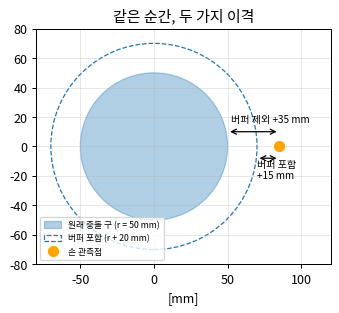

In [4]:
fig, ax = plt.subplots(figsize=(5, 3.4))
ax.add_patch(plt.Circle((0, 0), 50, color='tab:blue', alpha=0.35, label='원래 충돌 구 (r = 50 mm)'))
ax.add_patch(plt.Circle((0, 0), 70, fill=False, ls='--', color='tab:blue', label='버퍼 포함 (r + 20 mm)'))
ax.plot(85, 0, 'o', color='orange', ms=8, label='손 관측점')
ax.annotate('', xy=(70, -8), xytext=(85, -8), arrowprops=dict(arrowstyle='<->'))
ax.text(70, -22, '버퍼 포함\n+15 mm', fontsize=8)
ax.annotate('', xy=(50, 10), xytext=(85, 10), arrowprops=dict(arrowstyle='<->'))
ax.text(52, 16, '버퍼 제외 +35 mm', fontsize=8)
ax.set_xlim(-80, 120); ax.set_ylim(-80, 80); ax.set_aspect('equal')
ax.set_xlabel('[mm]'); ax.legend(fontsize=7, loc='lower left'); ax.set_title('같은 순간, 두 가지 이격')
plt.show()

**예측해 보기:** 61개 구가 모두 똑같이 20 mm씩 부풀었다. 그렇다면 전체 구간의 **최솟값**도 버퍼 포함과 버퍼 제외가 정확히 20 mm 차이 날까?

In [5]:
B = {c: next(e for e in E[c]['arrival-events'] if e['goal_index'] == 1) for c in CONDITIONS}   # B 도달 이벤트

print(f'{"조건":5s} {"버퍼 포함 최소":>12s} {"버퍼 제외 최소":>12s} {"차이":>7s} {"시점":>9s}  가장 가까운 링크')
for c in CONDITIONS:
    step = col(c, 'step')
    sel = (step >= B[c]['command_step']) & (step <= B[c]['arrival_step'])     # A→B 구간
    gap = col(c, 'original_surface_clearance_m')[sel] * 1000                 # 버퍼 포함 [mm]
    i = int(np.nanargmin(gap))
    row = [r for r, s in zip(E[c]['metrics'], sel) if s][i]
    print(f'{c:5s} {gap[i]:10.2f} mm {gap[i] + 20:10.2f} mm {20.0:5.1f}mm  step {row["step"]}  {row["nearest_observed_surface_link"]}')

조건        버퍼 포함 최소     버퍼 제외 최소      차이        시점  가장 가까운 링크
R         -29.54 mm      -9.54 mm  20.0mm  step 163  panda_link5
LOW       -11.20 mm       8.80 mm  20.0mm  step 169  panda_link7
HIGH       40.43 mm      60.43 mm  20.0mm  step 165  panda_hand


**결과 해석:**
- 같은 점·같은 구 집합에서 모든 구가 똑같이 20 mm 커졌으므로 최솟값도 정확히 20 mm 차이 난다. 그래서 두 값 중 어느 것을 쓰는지만 밝히면 된다. 섞어 쓰면 20 mm짜리 착각이 생긴다.
- R은 버퍼를 빼도 −9.5 mm다. 원래 구도 손 관측점과 겹쳤다는 뜻이다(가장 가까운 곳은 팔 중간의 `panda_link5`).
- LOW는 버퍼 제외 +8.8 mm, 버퍼 포함 −11.2 mm다. 원래 구는 손에 닿지 않았지만 계획용 여유(20 mm)는 지키지 못했다.
- HIGH는 버퍼를 포함해도 +40.4 mm다. η 73.52 mm보다는 작다. η가 보장 거리가 아니라는 11 노트의 내용과 맞다.

### 시간에 따른 이격
최솟값 하나만 보면 언제, 얼마나 오래 가까웠는지 알 수 없다. 시간에 따른 그래프로 본다.

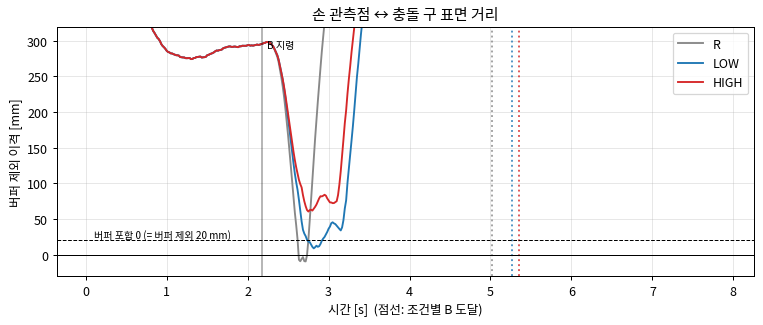

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.6))
for c in CONDITIONS:
    t = col(c, 'sim_s')
    ax.plot(t, col(c, 'original_surface_clearance_m') * 1000 + 20, color=COLORS[c], label=c)
    ax.axvline(B[c]['arrival_sim_s'], color=COLORS[c], ls=':', alpha=0.8)
ax.axhline(0, color='k', lw=0.8)
ax.axhline(20, color='k', lw=0.8, ls='--'); ax.text(0.1, 24, '버퍼 포함 0 (= 버퍼 제외 20 mm)', fontsize=8)
ax.axvline(B['R']['command_sim_s'], color='k', alpha=0.3); ax.text(B['R']['command_sim_s'] + 0.05, 290, 'B 지령', fontsize=8)
ax.set(xlabel='시간 [s]  (점선: 조건별 B 도달)', ylabel='버퍼 제외 이격 [mm]', ylim=(-30, 320))
ax.set_title('손 관측점 ↔ 충돌 구 표면 거리'); ax.legend(); plt.show()

**결과 해석:** B 지령 직후 세 조건 모두 손에 다가간다. 가장 가까운 순간 R은 0 아래로 내려가고, LOW는 0 근처까지, HIGH는 훨씬 위에서 멈췄다가 멀어진다. 가까운 구간의 길이는 1초 안쪽이다. 손 관측점이 없는 스텝은 그래프가 끊긴다(결측).

**직접 해보기:** 위 그래프에서 `+ 20`을 지우고 다시 그려 보자. 0 기준선이 무엇을 뜻하게 되는지 말해 보자.
<details><summary>답</summary>

버퍼 포함 이격이 된다. 이때 0 아래는 "계획용으로 부풀린 구가 손 관측점에 닿았다"는 뜻이고, 원래 구가 닿았다는 뜻은 아니다.
</details>

## 3. 지표 2 — 경로: 어디로 돌아갔나

### 문제
이격이 다르다는 것은 알았다. 로봇이 **어느 방향으로** 피했기에 이격이 달라졌을까?

### 아이디어
엔드이펙터(EE, 그리퍼 끝)의 위치를 위에서 본 그림과 정면에서 본 그림으로 그리고, 손 관측 패치 위치를 함께 표시한다.

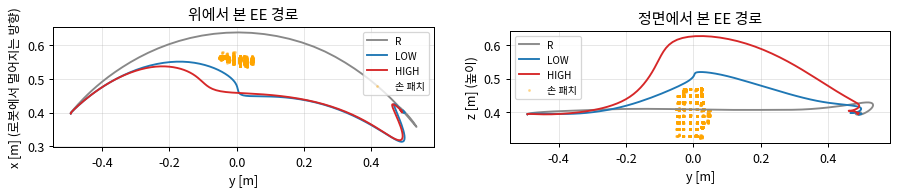

In [7]:
anch = np.array([a for p in E['HIGH']['patches-per-frame'] for a in p['anchors']])   # 손 패치 (전 프레임)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
for c in CONDITIONS:
    ee = np.array([r['ee_position'] for r in E[c]['metrics']])
    sel = (col(c, 'goal_index') == 1) & (col(c, 'step') <= B[c]['arrival_step'])        # A→B 구간
    ax[0].plot(ee[sel, 1], ee[sel, 0], color=COLORS[c], label=c)
    ax[1].plot(ee[sel, 1], ee[sel, 2], color=COLORS[c], label=c)
ax[0].scatter(anch[:, 1], anch[:, 0], s=2, c='orange', alpha=0.3, label='손 패치')
ax[1].scatter(anch[:, 1], anch[:, 2], s=2, c='orange', alpha=0.3, label='손 패치')
ax[0].set(xlabel='y [m]', ylabel='x [m] (로봇에서 멀어지는 방향)', title='위에서 본 EE 경로')
ax[1].set(xlabel='y [m]', ylabel='z [m] (높이)', title='정면에서 본 EE 경로')
for a in ax:
    a.set_aspect('equal'); a.legend(fontsize=8)
plt.show()

In [8]:
print('EE가 손 정면(y = 0)을 지나는 순간의 위치')
for c in CONDITIONS:
    ee = np.array([r['ee_position'] for r in E[c]['metrics']])
    g = col(c, 'goal_index')
    j = next(j for j in range(1, len(ee)) if g[j] == 1 and ee[j - 1, 1] < 0 <= ee[j, 1])
    a = -ee[j - 1, 1] / (ee[j, 1] - ee[j - 1, 1])           # 두 스텝 사이 선형 보간
    p = ee[j - 1] + a * (ee[j] - ee[j - 1])
    print(f'  {c:5s} x = {p[0]:.3f} m, z = {p[2]:.3f} m')

EE가 손 정면(y = 0)을 지나는 순간의 위치
  R     x = 0.638 m, z = 0.409 m
  LOW   x = 0.480 m, z = 0.506 m
  HIGH  x = 0.459 m, z = 0.626 m


**결과 해석:**
- 손 패치는 x ≈ 0.55~0.58 m, 높이 z ≈ 0.32~0.47 m에 있다.
- R은 손보다 바깥(x ≈ 0.64 m)으로 크게 돌지만 **손 높이 범위 안**(z ≈ 0.41 m)을 지나간다. EE는 손을 비켜 갔어도 팔 중간(`panda_link5`)이 손 관측면과 겹쳤다. EE 경로만 봐서는 충돌을 판단할 수 없다는 예다.
- LOW와 HIGH는 로봇 쪽으로 물러나며(x 감소) 손 **위로** 넘어간다. HIGH가 가장 높다(z ≈ 0.63 m).

**한 문장으로:** 같은 입력인데 HIGH만 훨씬 높이 넘어간 이유를 η와 비용으로 설명해 보자.

## 4. 지표 3 — 도달과 시간: 피하느라 얼마나 늦어졌나

### 문제
멀리 피하면 안전하지만 늦어질 수 있다. 회피가 작업(B에 가기)을 얼마나 방해했을까?

### 아이디어
"도착했다"의 기준을 먼저 정해야 한다. 이 실험은 **실제 EE가 목표에서 위치 10 mm 이내 그리고 자세 0.05 rad 이내**에 처음 들어온 순간을 도달로 본다. 도달하면 다음 스텝에 다음 목표를 지령한다. **A→B 시간**은 B 지령부터 실제 B 도달까지의 시뮬레이션 시간이다.

In [9]:
print(f'{"조건":5s} {"B 지령":>8s} {"B 도달":>8s} {"A→B 시간":>9s} {"B 위치 오차":>11s} {"B 자세 오차":>11s}')
for c in CONDITIONS:
    b = B[c]
    print(f'{c:5s} {b["command_sim_s"]:7.3f}s {b["arrival_sim_s"]:7.3f}s {b["duration_s"]:8.3f}s '
          f'{b["arrival_position_error_m"] * 1000:9.2f}mm {b["arrival_orientation_error_rad"]:9.4f}rad')

조건        B 지령     B 도달    A→B 시간     B 위치 오차     B 자세 오차
R       2.183s   5.017s    2.833s      2.44mm    0.0475rad
LOW     2.183s   5.267s    3.083s      9.77mm    0.0321rad
HIGH    2.183s   5.350s    3.167s      9.89mm    0.0282rad


**결과 해석:** 세 조건 모두 B에 도달했다. R 2.83 s → LOW 3.08 s → HIGH 3.17 s로, 멀리 피할수록 조금 늦어졌다. LOW → HIGH에서 최소 이격은 약 52 mm 늘었고 시간은 약 0.08 s 늘었다. 도달 오차는 모두 기준(10 mm, 0.05 rad) 안이다.

다만 "η가 크면 항상 더 오래 걸린다"고 일반화하면 안 된다. 어떤 우회 경로를 고르느냐가 시간을 정한다. 13 노트의 실습에서는 η를 키웠더니 오히려 더 빨리 도착하는 경우가 나온다.

## 5. 숫자의 출처 확인 — README 표를 로그에서 다시 계산하기

### 문제
레포 README의 결과 표(`docs/data/comparison.csv`)는 믿을 수 있을까? 결과를 읽는 사람이 할 수 있는 가장 확실한 확인은 **원본 로그에서 직접 다시 계산해 보는 것**이다.

In [10]:
with open(REPO / 'docs' / 'data' / 'comparison.csv') as f:
    ref = {r['condition']: r for r in csv.DictReader(f)}

checks = 0; ok = 0
for c in CONDITIONS:
    b, step = B[c], col(c, 'step')
    sel = (step >= b['command_step']) & (step <= b['arrival_step'])
    gap = col(c, 'original_surface_clearance_m')[sel] * 1000
    mine = {'min_buffered_sphere_clearance_mm': np.nanmin(gap), 'min_bare_sphere_clearance_mm': np.nanmin(gap) + 20,
            'buffered_negative_samples': (gap < 0).sum(), 'valid_samples': np.isfinite(gap).sum(),
            'A_arrival_s': E[c]['arrival-events'][0]['arrival_sim_s'], 'B_command_s': b['command_sim_s'],
            'B_arrival_s': b['arrival_sim_s'], 'AB_duration_s': b['duration_s']}
    for k, v in mine.items():
        checks += 1; ok += abs(float(v) - float(ref[c][k])) < 1e-6
print(f'comparison.csv와 일치한 항목: {ok} / {checks}')

comparison.csv와 일치한 항목: 24 / 24


**결과 해석:** 모든 항목이 일치한다. README의 이격·시간 수치가 `metrics.jsonl`과 `arrival-events.jsonl`에서 나왔다는 것을 직접 확인한 셈이다.

## 6. 지표 4 — 추종: 실제 로봇은 계획대로 움직였나

### 문제
01 노트의 "마찰 있는 카트"를 떠올려 보자. 모델로 계획한 대로 명령을 줘도 실제 카트는 다르게 움직였다. Isaac Sim의 Franka도 마찬가지다. 실제 관절은 계획과 얼마나 달랐을까?

### 아이디어
두 가지 차이를 본다.

| 로그 값 | 뜻 |
|---|---|
| `command_actual_q_max_rad` | 이번 스텝 위치 명령 − 실제 관절 각도 (7관절 중 최대). 관절 드라이브가 따라가야 할 거리 |
| `filtered_actual_q_max_rad` | MPPI가 계획을 시작한 상태 − 실제 관절 각도. cuRobo 상태 필터(09 노트) 때문에 생기는 차이 |

이 실험은 매 스텝 **실제로 측정한 관절 상태**를 MPC에 넣는다(`state_input = measured`). 그래도 cuRobo가 측정값을 그대로 쓰지 않고 `새 값 = 0.1 × 측정 + 0.9 × 이전 값`처럼 섞기 때문에, 계획 시작 상태와 실제 상태 사이에 차이가 생긴다.

R     명령−실제 최대 2.86°, 계획 시작−실제 최대 1.28°
LOW   명령−실제 최대 2.66°, 계획 시작−실제 최대 2.09°
HIGH  명령−실제 최대 2.70°, 계획 시작−실제 최대 1.93°


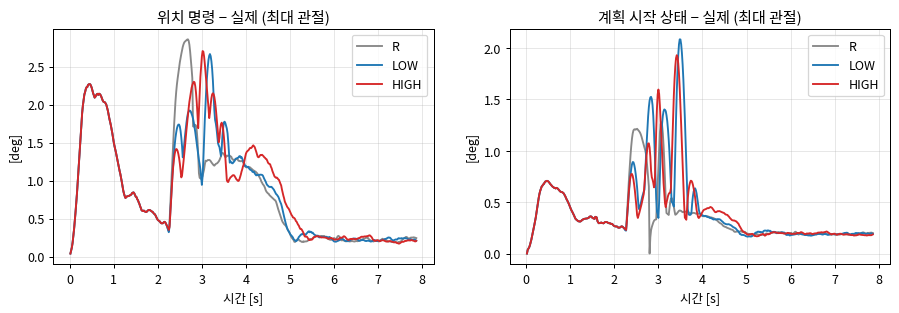

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
for c in CONDITIONS:
    t = col(c, 'sim_s')
    ax[0].plot(t, np.degrees(col(c, 'command_actual_q_max_rad')), color=COLORS[c], label=c)
    ax[1].plot(t, np.degrees(col(c, 'filtered_actual_q_max_rad')), color=COLORS[c], label=c)
ax[0].set(title='위치 명령 − 실제 (최대 관절)', ylabel='[deg]', xlabel='시간 [s]')
ax[1].set(title='계획 시작 상태 − 실제 (최대 관절)', ylabel='[deg]', xlabel='시간 [s]')
for a in ax: a.legend()
plt.show()
for c in CONDITIONS:
    print(f'{c:5s} 명령−실제 최대 {np.degrees(col(c, "command_actual_q_max_rad").max()):.2f}°, '
          f'계획 시작−실제 최대 {np.degrees(col(c, "filtered_actual_q_max_rad").max()):.2f}°')

**결과 해석:**
- 명령과 실제의 차이는 최대 약 3°다. 빠르게 움직이는 구간에서 커지고 멈추면 0에 가까워진다. 관절 드라이브(13 노트의 PD)가 한 스텝 안에 명령을 다 따라가지 못하는 양이다.
- 계획 시작 상태와 실제의 차이도 최대 약 2°다. "측정 상태를 넣었다"가 "MPPI가 정확히 지금 상태에서 계획했다"를 뜻하지는 않는다.
- 이 차이들이 이격 결과를 얼마나 바꿨는지는 이 로그만으로는 알 수 없다. 필터나 드라이브만 바꾼 비교 실행이 따로 필요하다.

## 7. 지표 5 — 안전 장치 점검: feasible과 속도 한계

### 문제
cuRobo는 계획마다 `feasible`(실행 가능) 여부를 알려 준다. 실험은 feasible이 아니면 로봇을 그 자리에 세우도록(`hold-measured`) 설정되어 있었다. 그렇다면 R이 손과 겹친 순간에 feasible은 어땠을까?

In [12]:
import xml.etree.ElementTree as ET
urdf = CUROBO / 'src/curobo/content/assets/robot/franka_description/franka_panda.urdf'
vlim = {j.get('name'): float(j.find('limit').get('velocity')) for j in ET.parse(urdf).getroot().findall('joint')
        if j.get('name').startswith('panda_joint') and j.find('limit') is not None}
vlim = np.array([vlim[f'panda_joint{i}'] for i in range(1, 8)])

for c in CONDITIONS:
    m = E[c]['metrics']
    feas = np.mean([all(r['feasible']) for r in m])
    hold = sum(r['hold_applied'] for r in m)
    v = np.abs(np.array([r['actual_velocity'] for r in m]))
    print(f'{c:5s} feasible {feas * 100:.0f}% | 정지(hold) {hold}회 | 관절 속도 / 한계 최대 {(v / vlim).max():.2f}')

R     feasible 100% | 정지(hold) 0회 | 관절 속도 / 한계 최대 0.85
LOW   feasible 100% | 정지(hold) 0회 | 관절 속도 / 한계 최대 0.69
HIGH  feasible 100% | 정지(hold) 0회 | 관절 속도 / 한계 최대 0.80


**결과 해석:**
- 세 조건 모두 모든 스텝이 feasible이었고, 정지 장치는 한 번도 작동하지 않았다. 관절 속도도 한계의 85% 이하였다.
- **R도 100% feasible이었다.** R은 원래 구 기준으로도 손 관측점과 9.5 mm 겹쳤지만 feasible이었다. feasible은 손과의 비접촉을 보장하지 않는다. 손 비용은 feasible 검사에 들어가지 않고(11 노트), R은 손 비용 자체가 없다.

## 8. 더 깊이 — MPPI 가중치는 어디에 몰렸나

05 노트에서 MPPI는 후보마다 softmax 가중치를 준다고 배웠다. LOW·HIGH 로그에는 매 스텝 마지막 반복의 후보 400개 중 **손 비용이 0보다 큰 후보 수**와, 그 후보들이 가진 **가중치 비율**이 남아 있다.

**예측해 보기:** 손 근처를 지나는 동안, 가중치는 손 비용이 0인 후보(손을 완전히 피하는 후보)에 몰렸을까, 손 비용이 있는 후보에 몰렸을까?

LOW   손 비용 후보가 있던 스텝 56개 중 가중치 절반 이상이 그 후보들에 몰린 스텝 55개
HIGH  손 비용 후보가 있던 스텝 61개 중 가중치 절반 이상이 그 후보들에 몰린 스텝 54개


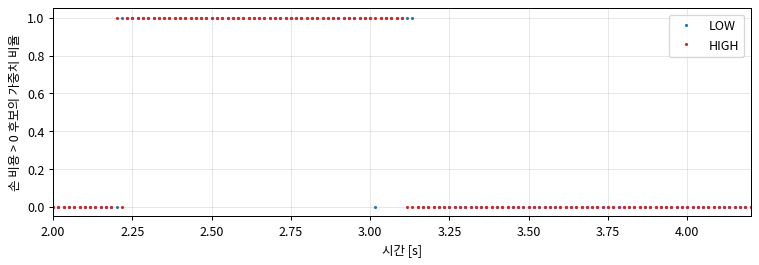

In [13]:
fig, ax = plt.subplots(figsize=(10, 3))
for c in ['LOW', 'HIGH']:
    t, nz, wm = col(c, 'sim_s'), col(c, 'target_nonzero_candidates'), col(c, 'target_weight_mass')
    ax.plot(t, wm, '.', ms=3, color=COLORS[c], label=c)
    on = nz > 0
    print(f'{c:5s} 손 비용 후보가 있던 스텝 {int(on.sum())}개 중 가중치 절반 이상이 그 후보들에 몰린 스텝 {int((wm[on] > 0.5).sum())}개')
ax.set(xlim=(2, 4.2), xlabel='시간 [s]', ylabel='손 비용 > 0 후보의 가중치 비율'); ax.legend(); plt.show()

**결과 해석:** 대부분의 스텝에서 가중치 절반 이상이 손 비용이 있는 후보에 몰렸다. 즉 선택된 계획은 손을 완전히 피하는 계획이 아니라, **손 비용을 조금 받으면서 목표 쪽으로 가는 절충안**이었다. 값이 0이나 1 근처에 몰리는 것은 β = 0.1에서 가중치가 한두 후보에 집중되기 때문이다(05 노트의 온도 β). 06 노트의 soft cost 절충이 실제 로봇에서 나타난 모습이다.

## 9. 해석 — 말할 수 있는 것과 말할 수 없는 것

결과를 읽는 마지막 단계는 주장의 범위를 정하는 것이다.

| 주장 | 판단 | 이유 |
|---|---|---|
| 이 장면에서 HIGH가 LOW보다 손에서 더 멀리 지나갔다 | **말할 수 있다** | 같은 입력·seed·설정, η만 다름. 버퍼 제외 최소 이격 +8.8 → +60.4 mm |
| R → LOW 개선은 질량 정책(η) 덕분이다 | **말할 수 없다** | R → LOW에는 손 패치 표현 도입 효과가 섞여 있다. η 효과는 LOW → HIGH로만 본다 |
| HIGH는 손에서 73.52 mm 이상 떨어진다 | **말할 수 없다** | η는 비용이 켜지는 거리일 뿐이다. 실제 최소는 버퍼 포함 +40.4 mm |
| R은 실제로 손에 부딪혔다 | **말할 수 없다** | 거리는 근사 구 ↔ 보이는 손 표면 점 기준이다. 실제 로봇 표면, 가려진 손 뒷면, ROI 밖 손끝은 이 거리에 없다 |
| η를 크게 하면 언제나 더 안전하다 | **말할 수 없다** | 장면 하나, seed 하나, 조건별 1회 실행. 통계적 일반화 불가 |
| 실제 로봇과 사람에게 안전하다 | **말할 수 없다** | 가상 로봇에 기록된 깊이를 재생한 실험이다. 실제 접촉력은 재지 않았다 |

## 핵심 정리

- 비교는 **하나만 바꾸고 나머지는 같게** 해야 해석된다. LOW → HIGH는 η만 다르고, R → LOW에는 두 효과가 섞인다. 세 조건의 A 도달 시각이 같은 것이 같은 조건의 증거다.
- 이격은 **무엇과 무엇 사이 거리인지**(근사 구 ↔ 관측점, 버퍼 포함/제외)를 항상 함께 말한다. 버퍼 포함과 제외는 정확히 20 mm 차이다.
- EE 경로만으로 충돌을 판단할 수 없다. R은 EE가 손을 비켜 갔지만 팔이 손과 겹쳤다.
- 실제 로봇은 계획을 몇 도씩 늦게 따라가고, feasible은 손과의 비접촉을 보장하지 않는다.
- README의 숫자는 원본 로그에서 다시 계산해 일치를 확인할 수 있다.

## 확인 문제

<details><summary>1. LOW의 최소 이격이 버퍼 제외 +8.8 mm, 버퍼 포함 −11.2 mm다. 이 두 값을 한 문장으로 해석하면?</summary>

원래 크기의 충돌 구는 손 관측점에 닿지 않았지만(8.8 mm 떨어짐), cuRobo가 계획할 때 두는 20 mm 여유는 지키지 못했다(11.2 mm 침범).
</details>

<details><summary>2. 세 조건의 A 도달 시각이 같은 것은 무엇을 뜻하나?</summary>

손 비용이 0인 구간에서는 세 조건의 계산이 완전히 같다는 뜻이다. 입력·seed·설정이 같게 맞춰져 있다는 확인이 되고, 조건 차이가 손 근처 구간에서만 생긴다는 것을 보여 준다.
</details>

<details><summary>3. "질량 가정이 회피 거리를 바꿨다"는 주장을 하려면 어떤 두 조건을 비교해야 하나? 왜?</summary>

LOW와 HIGH. 두 조건은 손 패치 표현이 같고 η(질량 가정에서 나온 값)만 다르다. R은 손 패치 표현 자체가 없어서 R과 비교하면 표현 효과가 섞인다.
</details>

<details><summary>4. 모든 스텝이 feasible이었는데 R이 손과 겹칠 수 있었던 이유는?</summary>

feasible 검사에는 손 비용이 들어가지 않는다. 또 R의 지도 기반 충돌 비용은 구 중심이 미관측 영역에 있으면 0이 되어 겹침을 보지 못했다(10 노트).
</details>

<details><summary>5. 결과의 일반성을 높이려면 어떤 실험을 더 해야 하나?</summary>

seed를 바꾼 반복 실행, 손 위치·자세를 바꾼 여러 장면, 다른 사람의 손. 그리고 거리를 실제 로봇 표면이나 손 전체 기준으로도 재는 분석.
</details>

## 실제 프로젝트에서는

| 이 노트 | 레포 위치 |
|---|---|
| 원본 로그 | `evidence/{R,LOW,HIGH}/` (`metrics.jsonl`, `arrival-events.jsonl` 등) |
| 이격 계산 (`original_surface_clearance_m`) | `experiment/target_margin.py`의 `clearance` |
| 도달 판정 10 mm · 0.05 rad, 다음 목표 지령 | `experiment/hand_experiment.py:287-296`, `experiment/goal_progress.py` |
| 한 스텝 기록 내용 | `experiment/hand_experiment.py:332-336` |
| 표·그림 생성 | `scripts/build_figures.py`, `docs/data/comparison.csv` |
| R 실패 원인 분석 | `docs/diagnosis.md` |

## 다음 노트

[13 · Isaac Sim 실습](13_isaacsim_lab.ipynb): 지금까지는 남이 돌린 로그를 읽었다. 이제 Isaac Sim에서 Franka와 MPPI를 직접 돌리고, η를 바꿔 가며 같은 지표로 결과를 비교해 본다.